# 📘 Notebook 05: Neurons and Layers, How Big and How Deep

### Course: *From Defaults to Decisions: Hyperparameters, Explained by Experiment*
**Instructor:** Ioannis Tsioulis

---

> 💡 **This notebook is already run.** Every number and chart below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab.
>
> ⏱️ **Training time and limitations.** About **ten minutes** on an ordinary processor. Every network is trained with early stopping on the validation loss (Notebook 02), so that a big network is not judged after it has overfitted. Fully connected networks on small images; for images, convolutional networks are better (see *From Papers to Practice*), but the lessons about **capacity** hold for every architecture.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Explain **capacity**: what the number of neurons (**width**) and layers (**depth**) control
- Run a **width sweep** and see where more neurons stop helping
- Compare **deep and narrow** with **shallow and wide** networks of the same size
- Count **parameters** and use them to compare architectures fairly
- Recognise when a network is **too small** (underfits) or **unnecessarily large**

> **Prerequisites:** [Notebook 02: Epochs and Early Stopping](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-defaults-to-decisions/02_epochs_and_early_stopping.ipynb).
>
> 🔭 **Why this notebook matters:** "how many neurons and layers?" is the question students ask most, and the answer most often given is a guess. The experiments below show how to find out: start small, grow until validation stops improving, and count the cost.

In [1]:
# Shared setup: the same data, model builder and training loop in every notebook of this course.
import warnings
warnings.filterwarnings("ignore")

import gzip, time, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.precision", 3)

BASE = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
def read_idx(name, header):
    return np.frombuffer(gzip.decompress(urllib.request.urlopen(BASE + name).read()), dtype=np.uint8, offset=header)

images = torch.tensor(read_idx("train-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
labels = torch.tensor(read_idx("train-labels-idx1-ubyte.gz", 8), dtype=torch.long)
X_test = torch.tensor(read_idx("t10k-images-idx3-ubyte.gz", 16).reshape(-1, 784), dtype=torch.float32) / 255
y_test = torch.tensor(read_idx("t10k-labels-idx1-ubyte.gz", 8), dtype=torch.long)
mean, std = images.mean(), images.std()
images, X_test = (images - mean) / std, (X_test - mean) / std

order = torch.randperm(len(images), generator=torch.Generator().manual_seed(0))
X_train, y_train = images[order[:10000]], labels[order[:10000]]       # 10,000 images to learn from
X_val, y_val = images[order[10000:15000]], labels[order[10000:15000]] # 5,000 to choose hyperparameters
print(f"train {len(X_train):,}   validation {len(X_val):,}   test {len(X_test):,}")

def make_mlp(hidden=(128,), activation=nn.ReLU, dropout=0.0, batchnorm=False):
    layers, width = [], 784
    for h in hidden:
        layers.append(nn.Linear(width, h))
        if batchnorm:
            layers.append(nn.BatchNorm1d(h))
        layers.append(activation())
        if dropout:
            layers.append(nn.Dropout(dropout))
        width = h
    layers.append(nn.Linear(width, 10))
    return nn.Sequential(*layers)

def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()

def fit(model, epochs=20, lr=1e-3, batch=128, optimizer="adam", weight_decay=0.0, scheduler=None, seed=0, X=None, y=None):
    """Train and return a history with one row per epoch."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    torch.manual_seed(seed)
    opts = {"sgd": lambda p: torch.optim.SGD(p, lr=lr, weight_decay=weight_decay),
            "momentum": lambda p: torch.optim.SGD(p, lr=lr, momentum=0.9, weight_decay=weight_decay),
            "rmsprop": lambda p: torch.optim.RMSprop(p, lr=lr, weight_decay=weight_decay),
            "adam": lambda p: torch.optim.Adam(p, lr=lr, weight_decay=weight_decay),
            "adamw": lambda p: torch.optim.AdamW(p, lr=lr, weight_decay=weight_decay)}
    opt = opts[optimizer](model.parameters())
    steps_per_epoch = (len(X) + batch - 1) // batch
    sched = scheduler(opt, epochs * steps_per_epoch) if scheduler else None
    rows, start = [], time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(X))
        total = 0.0
        for i in range(0, len(X), batch):
            idx = perm[i:i + batch]
            loss = F.cross_entropy(model(X[idx]), y[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            if sched:
                sched.step()
            total += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            val_loss = F.cross_entropy(model(X_val), y_val).item()
        rows.append({"epoch": epoch, "train loss": total / len(X), "val loss": val_loss,
                     "train acc": accuracy(model, X, y), "val acc": accuracy(model, X_val, y_val)})
    history = pd.DataFrame(rows).set_index("epoch")
    history.attrs["seconds"] = time.time() - start
    return history

train 10,000   validation 5,000   test 10,000


In [2]:
import copy

def train_es(model, max_epochs=80, patience=5, lr=1e-3, seed=0):
    """Train with early stopping on validation loss; return best validation accuracy and epochs used."""
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_loss, best_state, best_epoch, waited, start = float("inf"), None, 0, 0, time.time()
    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(len(X_train))
        for i in range(0, len(X_train), 128):
            idx = perm[i:i + 128]
            loss = F.cross_entropy(model(X_train[idx]), y_train[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            vl = F.cross_entropy(model(X_val), y_val).item()
        if vl < best_loss:
            best_loss, best_state, best_epoch, waited = vl, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            waited += 1
            if waited >= patience:
                break
    model.load_state_dict(best_state)
    return {"parameters": sum(p.numel() for p in model.parameters()), "best epoch": best_epoch,
            "train acc": accuracy(model, X_train, y_train), "val acc": accuracy(model, X_val, y_val),
            "seconds": time.time() - start}

## 1. Width: how many neurons?

### Intuition first
Each hidden neuron learns one feature of the input, a combination of pixels. More neurons can represent more features: the network's **capacity** grows. Too few, and the network cannot represent the patterns it needs (it **underfits**). Too many, and it has room to memorise the training images; with early stopping that mostly costs time rather than accuracy.

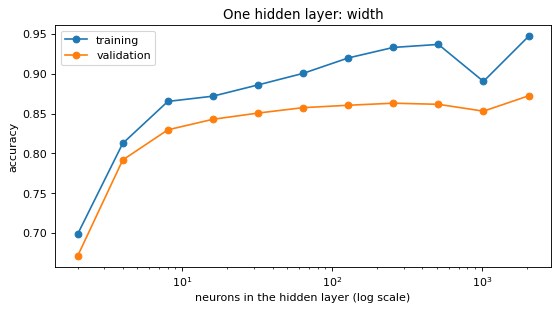

,parameters,best epoch,train acc,val acc,seconds
neurons,,,,,
2,1.600e+03,78.0,0.699,0.671,18.875
4,3.190e+03,38.0,0.813,0.792,9.127
8,6.370e+03,22.0,0.865,0.830,4.963
16,1.273e+04,13.0,0.872,0.843,3.748
32,2.545e+04,11.0,0.886,0.851,4.589
64,5.089e+04,11.0,0.900,0.857,7.557
128,1.018e+05,11.0,0.920,0.860,7.916
256,2.035e+05,11.0,0.933,0.863,10.782
512,4.070e+05,11.0,0.937,0.862,14.070


In [3]:
width_rows = {}
for width in [2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048]:
    width_rows[width] = train_es(make_mlp(hidden=(width,)))
widths = pd.DataFrame(width_rows).T.rename_axis("neurons")
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(widths.index, widths["train acc"], marker="o", label="training")
ax.semilogx(widths.index, widths["val acc"], marker="o", label="validation")
ax.set_xlabel("neurons in the hidden layer (log scale)"); ax.set_ylabel("accuracy"); ax.legend(); ax.set_title("One hidden layer: width")
plt.show()
widths.round(3)

**What we see.** A textbook capacity curve, with one honest wrinkle:
- With **2** neurons the network badly underfits (67.1%): two features cannot describe ten kinds of clothing. Accuracy climbs fast up to **16 to 32** neurons (84 to 85%).
- From **64** to **2,048** neurons, validation accuracy creeps from 85.7% to 87.2%, while the number of parameters grows **32-fold** and the training time about five-fold. The returns diminish sharply.
- The training accuracy keeps rising with width (to 94.7%), so the gap between training and validation grows: larger networks fit the training set more closely, and early stopping keeps that from hurting validation.
- The **1,024** point is a dip (85.3%, stopped at epoch 4): early stopping with patience 5 stopped after an unlucky early epoch. Single runs are noisy; Section 4 repeats them.

## 2. Depth: how many layers?

We stack 1 to 6 hidden layers of 128 neurons each.

In [4]:
depth_rows = {}
for depth in [1, 2, 3, 4, 6]:
    depth_rows[depth] = train_es(make_mlp(hidden=(128,) * depth))
pd.DataFrame(depth_rows).T.rename_axis("hidden layers of 128").round(3)

,parameters,best epoch,train acc,val acc,seconds
hidden layers of 128,,,,,
1,101770.0,11.0,0.916,0.860,6.930
2,118282.0,11.0,0.915,0.861,8.502
3,134794.0,10.0,0.904,0.857,9.582
4,151306.0,11.0,0.906,0.856,12.885
6,184330.0,15.0,0.918,0.859,21.178


**What we see.** Adding layers of 128 neurons does **not** help on this problem: 86.0%, 86.1%, 85.7%, 85.6% and 85.9% for 1 to 6 layers, all within the seed-to-seed spread of Notebook 01, while the training time triples. For small images treated as flat lists of pixels, one hidden layer already captures most of what a fully connected network can learn; depth pays off when the problem has a hierarchy that layers can exploit, as convolutional networks show for images.

## 3. Same size, different shape

A fair comparison of shapes keeps the **number of parameters** about the same. Here are four networks of roughly 100,000 parameters.

In [5]:
shapes = {"1 layer of 128": (128,), "2 layers of 110": (110, 110), "4 layers of 90": (90, 90, 90, 90), "a funnel 112-64-32": (112, 64, 32)}
shape_rows = {}
for name, hidden in shapes.items():
    shape_rows[name] = train_es(make_mlp(hidden=hidden))
pd.DataFrame(shape_rows).T.round(3)

,parameters,best epoch,train acc,val acc,seconds
1 layer of 128,101770.0,15.0,0.934,0.864,11.200
2 layers of 110,99670.0,15.0,0.936,0.858,11.523
4 layers of 90,96130.0,11.0,0.900,0.850,11.736
a funnel 112-64-32,97562.0,11.0,0.899,0.855,11.002


**What we see.** At about **100,000** parameters each, the four shapes land within about 1.4 points of each other: 86.4% for one layer of 128, 85.8% for two layers, 85.0% for four, 85.5% for the funnel. Here, shallow and wide is at least as good as deep and narrow. (One layer of 128 scores 86.0% in Section 2 and 86.4% here: the same architecture, but its starting weights were drawn at a different moment of the random sequence. Another reminder of how much noise single runs carry.)

## 4. Is the difference real? Repeat with several seeds

In [6]:
repeat = {}
for name, hidden in [("1 layer of 128", (128,)), ("2 layers of 110", (110, 110)), ("1 layer of 1024", (1024,))]:
    scores = [train_es(make_mlp(hidden=hidden), seed=s)["val acc"] for s in range(4)]
    repeat[name] = {"mean val acc": np.mean(scores), "std": np.std(scores), "min": np.min(scores), "max": np.max(scores)}
pd.DataFrame(repeat).T.round(4)

,mean val acc,std,min,max
1 layer of 128,0.857,0.005,0.849,0.860
2 layers of 110,0.860,0.003,0.856,0.862
1 layer of 1024,0.861,0.005,0.854,0.867


**What we see.** Repeated with four seeds, the averages are **85.7%** (1 × 128), **86.0%** (2 × 110) and **86.1%** (1 × 1,024), with standard deviations of 0.3 to 0.5 points and overlapping ranges. **None of these differences is real**: eight times more neurons buy nothing measurable here. The single-run differences in Sections 1 to 3 that looked like a pattern were mostly noise. A practical rule: on this problem, about 64 to 128 neurons in one layer is enough, and anything bigger only costs time.

## ⚠️ Common pitfalls

- **Judging a large network without early stopping.** Trained for a fixed long time, it overfits and looks worse than it is.
- **Comparing shapes of different sizes.** Count parameters; otherwise you compare size, not shape.
- **Adding layers to fix a learning-rate or data problem.** If training accuracy is high and validation low, more capacity makes it worse.
- **Believing a one-run difference of a few tenths of a percent.** Repeat with several seeds (Section 4).
- **Copying "64-32-16" from a tutorial.** Start with one hidden layer, grow width until validation stops improving, then try a second layer.

## ✏️ Exercises

### Exercise 1 (Less data)
Repeat the width sweep (8, 64, 512, 2048 neurons) on only the first **1,000** training images. Where does validation accuracy peak now?

In [7]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
full_X, full_y = X_train, y_train
X_train, y_train = full_X[:1000], full_y[:1000]
small = {w: train_es(make_mlp(hidden=(w,)))["val acc"] for w in [8, 64, 512, 2048]}
X_train, y_train = full_X, full_y
print({k: round(v, 4) for k, v in small.items()})
```

*With ten times less data, the useful capacity is smaller: very wide networks gain little or nothing, and the gap between training and validation is larger. The right size depends on how much data you have.*
</details>

### Exercise 2 (Count the cost)
For widths 128 and 2048, measure the time to predict all 10,000 test images (`time.time()` around `model(X_test)`), and compare with their validation accuracies from Section 1.

In [8]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
for w in [128, 2048]:
    m = make_mlp(hidden=(w,)); train_es(m)
    start = time.time()
    with torch.no_grad():
        for _ in range(10):
            m(X_test)
    print(f"{w} neurons: {1000 * (time.time() - start) / 10:.1f} ms for 10,000 images, val acc {accuracy(m, X_val, y_val):.4f}")
```

*The wide network is many times slower and larger for at most a small gain in accuracy. In deployment, size and speed are hyperparameters too.*
</details>

## 🔑 Key takeaways

- **Width** and **depth** set the network's **capacity**; too little underfits, beyond a point more adds cost rather than accuracy.
- With **early stopping**, large networks rarely hurt accuracy on their own, but they cost time and memory.
- Compare shapes at a **fixed number of parameters**, and repeat with several **seeds**.
- A practical recipe: start with one hidden layer, widen until validation stops improving, then try one more layer.

---
**Next:** *Notebook 06: Activation Functions*, what non-linearity goes between the layers.

---
*© Ioannis Tsioulis. *From Defaults to Decisions: Hyperparameters, Explained by Experiment*. Prepared for educational use.*